# Tidal Water Level Analysis with TSGAM

Configuration-driven analysis notebook for NOAA CO-OPS water levels and NOAA NCEI LCD meteorology.

This notebook focuses on:
- exploring the tidal and meteorological datasets
- motivating the TSGAM basis choices from the data itself
- showing how meteorological regressors change the model fit
- contrasting two stations with different tidal regimes

In [1]:
import sys
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from datetime import datetime
try:
    import seaborn as sns
except ImportError:
    sns = None

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

EXAMPLES_DIR = PROJECT_ROOT / "examples"
for path in (PROJECT_ROOT / "src", EXAMPLES_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from common_cli import set_journal_style
from example_tidal import (
    STATION_CATALOG,
    TIDAL_COMPONENT_LABELS,
    TIDAL_CONSTITUENT_HARMONICS,
    TIDAL_CONSTITUENT_PERIODS_HOURS,
    TIDE_TO_WEATHER,
    download_lcd_weather,
    download_tidal_data,
    load_lcd_weather,
    load_tidal_data,
    merge_tidal_weather,
)
from run_tidal import (
    _build_tidal_configs,
    _fit_single_tidal,
    _make_multi_periodic,
    _make_spline_configs,
    _tidal_metrics,
)
from tidal_analysis_helpers import (
    build_day_hour_matrix,
    compute_lagged_correlation,
    compute_periodogram,
    extract_fourier_components,
    infer_samples_per_hour,
)
from tsgam_estimator import (
    TsgamArConfig,
    TsgamEstimator,
    TsgamEstimatorConfig,
    TsgamMultiPeriodicConfig,
    TsgamOutlierConfig,
    TsgamSolverConfig,
    TsgamTrendConfig,
    TrendType,
)

set_journal_style()
if sns is not None:
    sns.set_theme(style="whitegrid")

pd.options.display.float_format = "{:,.4f}".format


In [2]:
station_options = [
    (f"{meta['name']} ({meta['tidal_regime']})", sid)
    for sid, meta in STATION_CATALOG.items()
]
station_dropdown = widgets.Dropdown(
    options=station_options,
    value="8518750",
    description="Station:",
    style={"description_width": "110px"},
    layout=widgets.Layout(width="400px"),
)
comparison_dropdown = widgets.Dropdown(
    options=[("None", "")] + station_options,
    value="8771450",
    description="Comparison:",
    style={"description_width": "110px"},
    layout=widgets.Layout(width="400px"),
)
solver_dropdown = widgets.Dropdown(
    options=["SCS", "ECOS", "OSQP", "CLARABEL"],
    value="SCS",
    description="Solver:",
    style={"description_width": "110px"},
    layout=widgets.Layout(width="250px"),
)
train_start_w = widgets.DatePicker(value=datetime.fromisoformat("2022-01-01"), description="Train start:", style={"description_width": "110px"})
train_end_w = widgets.DatePicker(value=datetime.fromisoformat("2023-12-31"), description="Train end:", style={"description_width": "110px"})
test_start_w = widgets.DatePicker(value=datetime.fromisoformat("2024-01-01"), description="Test start:", style={"description_width": "110px"})
test_end_w = widgets.DatePicker(value=datetime.fromisoformat("2024-03-31"), description="Test end:", style={"description_width": "110px"})
download_toggle = widgets.ToggleButton(value=False, description="Download fresh data", icon="download")

config_box = widgets.VBox([
    widgets.HBox([station_dropdown, comparison_dropdown]),
    widgets.HBox([solver_dropdown, download_toggle]),
    widgets.HBox([train_start_w, train_end_w]),
    widgets.HBox([test_start_w, test_end_w]),
])
display(config_box)


In [3]:
STATION = station_dropdown.value
COMPARISON_STATION = comparison_dropdown.value or None
TRAIN_START = train_start_w.value
TRAIN_END = train_end_w.value
TEST_START = test_start_w.value
TEST_END = test_end_w.value
SOLVER = solver_dropdown.value
RUN_DOWNLOADS = download_toggle.value

DATA_DIR = EXAMPLES_DIR / "data" / "tidal"
station_meta = STATION_CATALOG[STATION]
weather_station, weather_name = TIDE_TO_WEATHER.get(STATION, (None, None))

if RUN_DOWNLOADS:
    data_file = download_tidal_data(
        DATA_DIR,
        station=STATION,
        begin_date=pd.Timestamp(TRAIN_START).strftime("%Y%m%d"),
        end_date=pd.Timestamp(TEST_END).strftime("%Y%m%d"),
    )
else:
    data_file = DATA_DIR / f"{STATION}_combined.csv"
    if not data_file.exists():
        data_file = download_tidal_data(
            DATA_DIR,
            station=STATION,
            begin_date=pd.Timestamp(TRAIN_START).strftime("%Y%m%d"),
            end_date=pd.Timestamp(TEST_END).strftime("%Y%m%d"),
        )

df = load_tidal_data(data_file)
weather_status = "no mapped LCD station"
if weather_station is not None:
    try:
        if RUN_DOWNLOADS:
            download_lcd_weather(
                DATA_DIR,
                station_id=weather_station,
                begin_year=pd.Timestamp(TRAIN_START).year,
                end_year=pd.Timestamp(TEST_END).year,
            )
        weather_df = load_lcd_weather(
            DATA_DIR,
            station_id=weather_station,
            begin_date=TRAIN_START,
            end_date=TEST_END,
        )
        df = merge_tidal_weather(df, weather_df)
        weather_status = f"merged LCD data from {weather_name}"
    except FileNotFoundError:
        weather_status = (
            f"missing LCD cache for {weather_name}; set RUN_DOWNLOADS=True to fetch it"
        )

samples_per_hour = infer_samples_per_hour(df.index)
freq_td = df.index.to_series().diff().median()
freq_label = (
    f"{int(freq_td.total_seconds() // 60)}min"
    if freq_td < pd.Timedelta("1h")
    else "1h"
)

df_train = df[TRAIN_START:TRAIN_END].copy()
df_test = df[TEST_START:TEST_END].copy()
for subset in (df_train, df_test):
    if subset.index.freq is None:
        subset.index.freq = pd.infer_freq(subset.index)

y_train = df_train["water_level"].to_numpy()
y_test = df_test["water_level"].to_numpy()

summary = pd.DataFrame(
    {
        "value": [
            station_meta["name"],
            station_meta["region"],
            station_meta["tidal_regime"],
            station_meta["notes"],
            weather_name or "none",
            weather_status,
            freq_label,
            samples_per_hour,
            len(df),
            len(df_train),
            len(df_test),
            df.index.min(),
            df.index.max(),
            ", ".join(df.columns),
        ]
    },
    index=[
        "station",
        "region",
        "regime",
        "notes",
        "weather station",
        "weather status",
        "sampling",
        "samples/hour",
        "rows",
        "train rows",
        "test rows",
        "start",
        "end",
        "columns",
    ],
)

summary


Loaded 19704 samples at 1h resolution
Date range: 2022-01-01 00:00:00 to 2024-03-31 23:00:00
Water level range: -0.605 to 2.628 m (MLLW)
Available met variables: pressure, water_temp
  LCD weather: 19675 hourly records
    air_temp: -15.6 to 35.0 °C
    wind_speed: 0.0 to 12.5 m/s


,value
station,"The Battery, NY"
region,Northeast Atlantic
regime,Semi-diurnal
notes,Storm surge from nor'easters; ~1.5 m tidal range
weather station,"Central Park, NY"
weather status,"merged LCD data from Central Park, NY"
sampling,1h
samples/hour,1
rows,19704
train rows,17497


## Data Overview

Start with the raw structure of the station record: long-range level behavior, weather covariates, within-day tidal patterning, and missingness.

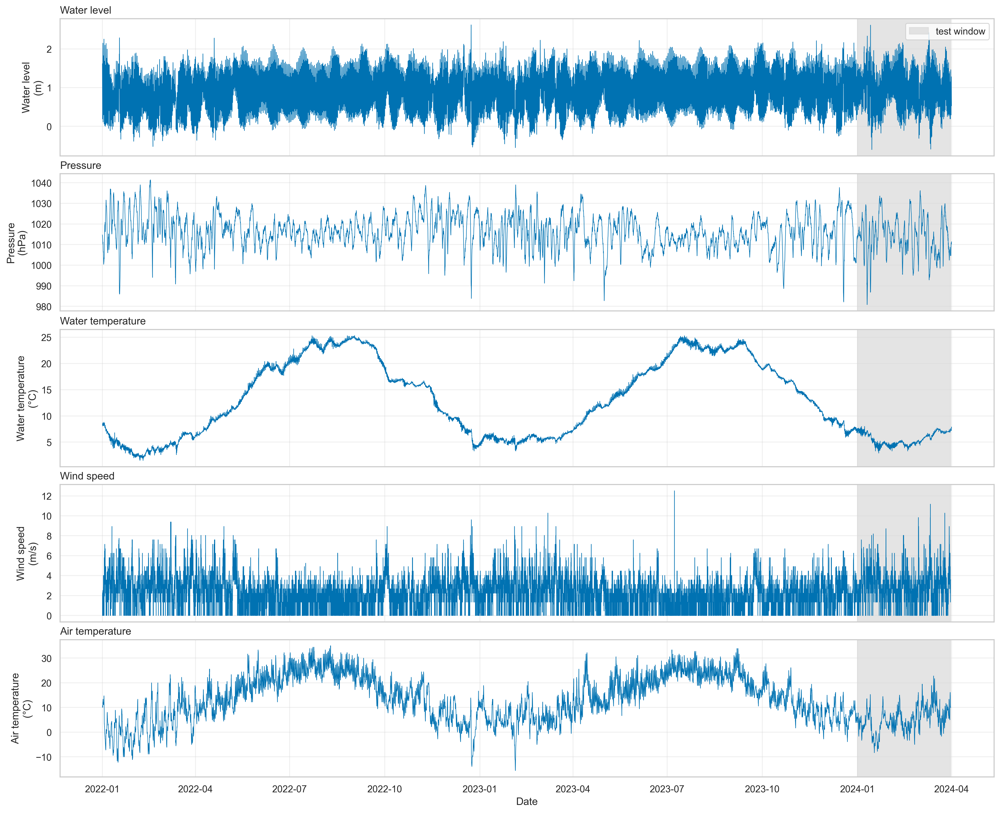

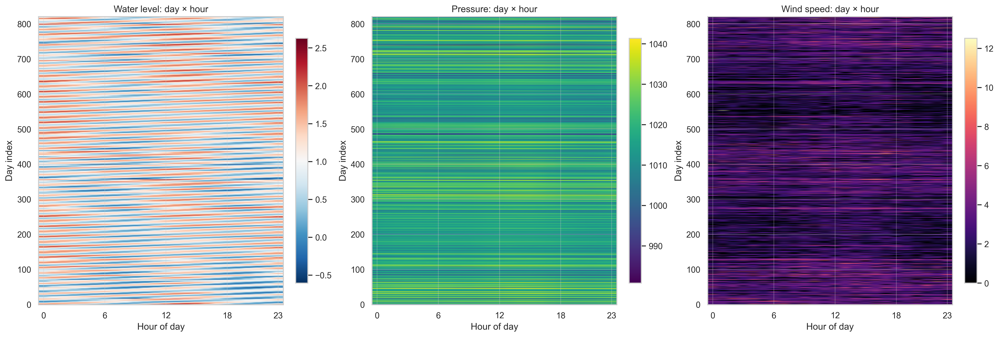

,pct_missing,non_null_count
wind_dir,0.1200,19681
wind_u,0.1200,19681
wind_v,0.1200,19681
air_temp,0.0900,19687
dewpoint,0.0900,19687
wind_speed,0.0900,19687
lcd_slp,0.0900,19687
water_level,0.0000,19704
pressure,0.0000,19704
water_temp,0.0000,19704


In [4]:
plot_specs = [
    ("water_level", "Water level", "m"),
    ("pressure", "Pressure", "hPa"),
    ("water_temp", "Water temperature", "°C"),
    ("wind_speed", "Wind speed", "m/s"),
    ("air_temp", "Air temperature", "°C"),
]
available_specs = [
    spec for spec in plot_specs if spec[0] in df.columns and df[spec[0]].notna().any()
]

fig, axes = plt.subplots(
    len(available_specs),
    1,
    figsize=(16, 2.6 * len(available_specs)),
    sharex=True,
    constrained_layout=True,
)
axes = np.atleast_1d(axes)
for ax, (column, label, unit) in zip(axes, available_specs, strict=True):
    ax.plot(df.index, df[column], color="#0072B2", linewidth=0.6)
    ax.axvspan(
        pd.Timestamp(TEST_START),
        pd.Timestamp(TEST_END),
        color="0.85",
        alpha=0.7,
        label="test window",
    )
    ax.set_ylabel(f"{label}\n({unit})")
    ax.set_title(label, loc="left")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Date")
plt.show()

heatmap_specs = [
    ("water_level", "Water level", "RdBu_r"),
    ("pressure", "Pressure", "viridis"),
    ("wind_speed", "Wind speed", "magma"),
]
available_heatmaps = [
    spec for spec in heatmap_specs if spec[0] in df.columns and df[spec[0]].notna().any()
]
fig, axes = plt.subplots(
    1,
    len(available_heatmaps),
    figsize=(6 * len(available_heatmaps), 6),
    constrained_layout=True,
)
axes = np.atleast_1d(axes)
for ax, (column, title, cmap) in zip(axes, available_heatmaps, strict=True):
    matrix = build_day_hour_matrix(df.index, df[column].to_numpy())
    image = ax.imshow(matrix.to_numpy(), aspect="auto", origin="lower", cmap=cmap)
    ax.set_title(f"{title}: day × hour")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Day index")
    ax.set_xticks([0, 6, 12, 18, 23])
    fig.colorbar(image, ax=ax, shrink=0.85)
plt.show()

missing_summary = (
    pd.DataFrame(
        {
            "pct_missing": (df.isna().mean() * 100).round(2),
            "non_null_count": df.notna().sum(),
        }
    )
    .sort_values("pct_missing", ascending=False)
)

missing_summary

### Interactive Time-Series Explorer

Use the sliders below to zoom into any window of the record.

In [ ]:
zoom_output = widgets.Output()
zoom_days = widgets.IntSlider(
    value=30, min=3, max=max(60, (df.index[-1] - df.index[0]).days),
    step=1, description="Window (days):",
    style={"description_width": "110px"},
    layout=widgets.Layout(width="600px"),
    continuous_update=False,
)
zoom_end_date = widgets.SelectionSlider(
    options=pd.date_range(df.index[0] + pd.Timedelta(days=3), df.index[-1], freq="1D").strftime("%Y-%m-%d").tolist(),
    value=(df.index[-1]).strftime("%Y-%m-%d"),
    description="End date:",
    style={"description_width": "110px"},
    layout=widgets.Layout(width="600px"),
    continuous_update=False,
)

def _update_zoom(*_args):
    with zoom_output:
        zoom_output.clear_output(wait=True)
        end = pd.Timestamp(zoom_end_date.value)
        start = end - pd.Timedelta(days=zoom_days.value)
        window = df.loc[start:end]
        if window.empty:
            print("No data in selected window.")
            return
        zoom_cols = [c for c in ["water_level", "pressure", "wind_speed"] if c in window.columns and window[c].notna().any()]
        fig, axes = plt.subplots(len(zoom_cols), 1, figsize=(16, 2.8 * len(zoom_cols)), sharex=True, constrained_layout=True)
        axes = np.atleast_1d(axes)
        for ax, col in zip(axes, zoom_cols):
            ax.plot(window.index, window[col], color="#0072B2", linewidth=0.8)
            ax.set_ylabel(col)
            ax.set_title(col, loc="left")
        axes[-1].set_xlabel("Date")
        fig.suptitle(f"Zoom: {start.date()} to {end.date()}", fontsize=13)
        plt.show()

zoom_days.observe(_update_zoom, names="value")
zoom_end_date.observe(_update_zoom, names="value")
display(widgets.VBox([widgets.HBox([zoom_days, zoom_end_date]), zoom_output]))
_update_zoom()


## Spectral Analysis and Met-Tide Correlations

The next step is to connect visible structure in the data to the TSGAM design: strong periodic peaks motivate the Fourier basis, while lagged meteorological relationships motivate spline regressors with lead/lag terms.

The constituent abbreviations used below follow the standard NOAA/NOS harmonic-constituent nomenclature, rather than names inferred by the estimator. NOAA's overview of the harmonic method describes how constituent names like `M2` and `S2` are used in tide prediction ([About Harmonic Constituents](https://tidesandcurrents.noaa.gov/about_harmonic_constituents.html)); the NOAA glossary defines common codes such as `M2`, `S2`, `N2`, `K1`, and `O1` ([NOAA Glossary](https://www.tidesandcurrents.noaa.gov/glossary.html)); and the NOS constituent table lists symbols and periods for `M2`, `S2`, `N2`, `K1`, `O1`, `Mf`, `Mm`, and `Msf` ([NOS Tidal Constituents and Arguments](https://coastalengineeringmanual.tpub.com/Part-II-Chap5/Part-II-Chap50021.htm)). In this notebook, `annual` is just a convenience label for a yearly basis term, not a standard named tidal constituent.


Loaded 19704 samples at 1h resolution
Date range: 2022-01-01 00:00:00 to 2024-03-31 23:00:00
Water level range: -0.796 to 1.198 m (MLLW)
Available met variables: pressure, water_temp, wind_speed, wind_u, wind_v
  LCD weather: 19681 hourly records
    air_temp: -5.6 to 39.4 °C
    wind_speed: 0.0 to 20.1 m/s


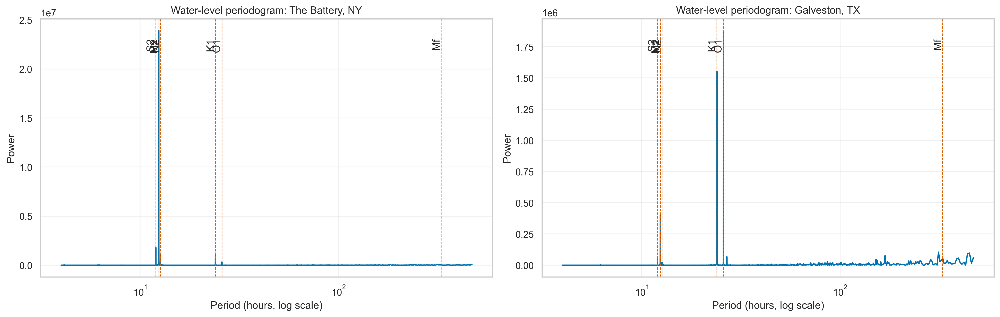

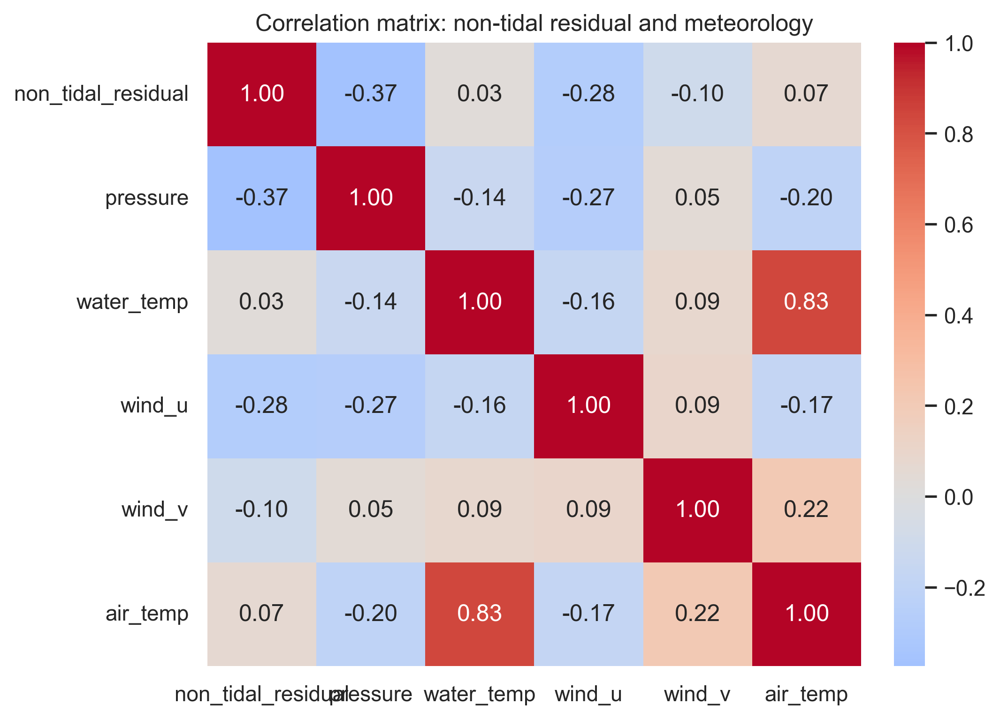

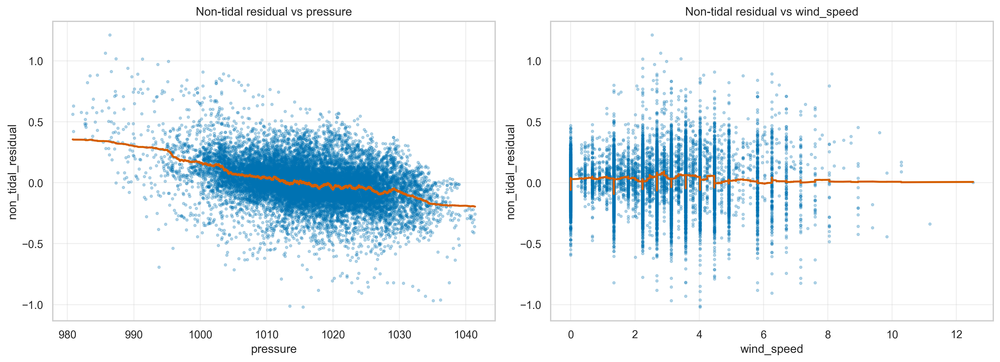

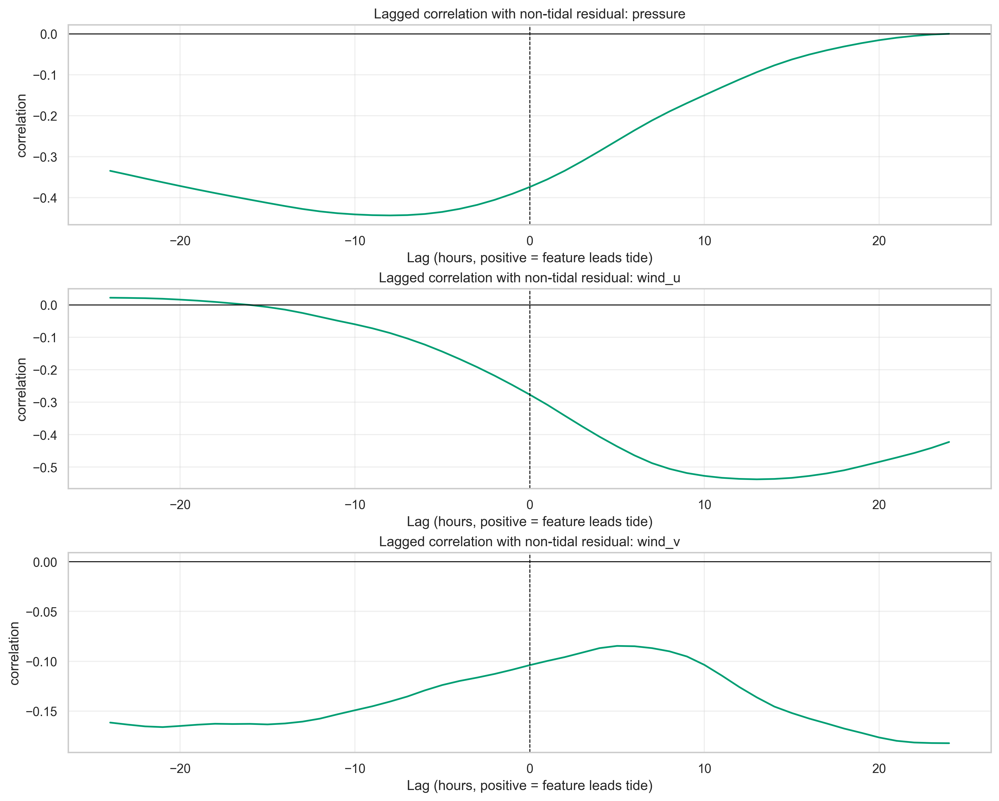

,period_hours,power
3340,12.4237,"23,926,930.8258"
3339,12.4159,"10,479,529.7332"
3341,12.4315,"1,979,408.5767"
3284,12.0000,"1,805,769.4751"
3338,12.4081,"1,400,002.1916"
3369,12.6551,"1,044,912.8277"
4103,23.9417,"971,275.9811"
3337,12.4003,"596,286.3524"
3370,12.6632,"566,322.5146"
3342,12.4394,"521,080.6527"


In [6]:
comparison_df = None
comparison_meta = None
comparison_samples_per_hour = None
comparison_weather_status = "not loaded"
if COMPARISON_STATION and COMPARISON_STATION != STATION:
    comparison_meta = STATION_CATALOG[COMPARISON_STATION]
    comparison_weather_station, comparison_weather_name = TIDE_TO_WEATHER.get(
        COMPARISON_STATION,
        (None, None),
    )
    if RUN_DOWNLOADS:
        comparison_file = download_tidal_data(
            DATA_DIR,
            station=COMPARISON_STATION,
            begin_date=pd.Timestamp(TRAIN_START).strftime("%Y%m%d"),
            end_date=pd.Timestamp(TEST_END).strftime("%Y%m%d"),
        )
    else:
        comparison_file = DATA_DIR / f"{COMPARISON_STATION}_combined.csv"
        if not comparison_file.exists():
            comparison_file = download_tidal_data(
                DATA_DIR,
                station=COMPARISON_STATION,
                begin_date=pd.Timestamp(TRAIN_START).strftime("%Y%m%d"),
                end_date=pd.Timestamp(TEST_END).strftime("%Y%m%d"),
            )

    comparison_df = load_tidal_data(comparison_file)
    if comparison_weather_station is not None:
        try:
            if RUN_DOWNLOADS:
                download_lcd_weather(
                    DATA_DIR,
                    station_id=comparison_weather_station,
                    begin_year=pd.Timestamp(TRAIN_START).year,
                    end_year=pd.Timestamp(TEST_END).year,
                )
            comparison_weather_df = load_lcd_weather(
                DATA_DIR,
                station_id=comparison_weather_station,
                begin_date=TRAIN_START,
                end_date=TEST_END,
            )
            comparison_df = merge_tidal_weather(comparison_df, comparison_weather_df)
            comparison_weather_status = f"merged LCD data from {comparison_weather_name}"
        except FileNotFoundError:
            comparison_weather_status = (
                f"missing LCD cache for {comparison_weather_name}; set RUN_DOWNLOADS=True to fetch it"
            )
    comparison_samples_per_hour = infer_samples_per_hour(comparison_df.index)

primary_spectrum = compute_periodogram(
    df.index,
    df["water_level"].to_numpy(),
    min_period_hours=4.0,
    max_period_hours=24.0 * 20,
)
if comparison_df is not None:
    comparison_spectrum = compute_periodogram(
        comparison_df.index,
        comparison_df["water_level"].to_numpy(),
        min_period_hours=4.0,
        max_period_hours=24.0 * 20,
    )
else:
    comparison_spectrum = None

constituents = dict(TIDAL_CONSTITUENT_PERIODS_HOURS)

fig, axes = plt.subplots(
    1,
    2 if comparison_spectrum is not None else 1,
    figsize=(16, 5),
    constrained_layout=True,
)
axes = np.atleast_1d(axes)
plot_payload = [(axes[0], primary_spectrum, station_meta["name"])]
if comparison_spectrum is not None:
    plot_payload.append((axes[1], comparison_spectrum, comparison_meta["name"]))
for ax, spectrum, title in plot_payload:
    ax.plot(spectrum["period_hours"], spectrum["power"], color="#0072B2")
    for label, period_hours in constituents.items():
        if spectrum["period_hours"].min() <= period_hours <= spectrum["period_hours"].max():
            ax.axvline(period_hours, color="#D55E00", linestyle="--", linewidth=0.8)
            ax.text(period_hours, ax.get_ylim()[1] * 0.92, label, rotation=90, va="top", ha="right")
    ax.set_xscale("log")
    ax.set_title(f"Water-level periodogram: {title}")
    ax.set_xlabel("Period (hours, log scale)")
    ax.set_ylabel("Power")
plt.show()

eda_preview_est = TsgamEstimator(
    config=TsgamEstimatorConfig(
        multi_periodic_config=_make_multi_periodic(samples_per_hour),
        exog_config=None,
        solver_config=TsgamSolverConfig(solver=SOLVER, verbose=False),
        random_state=42,
    )
)
eda_preview_X = pd.DataFrame(index=df.index)
eda_preview_est.fit(eda_preview_X, df["water_level"].to_numpy())
non_tidal_residual = pd.Series(
    df["water_level"].to_numpy() - eda_preview_est.predict(eda_preview_X),
    index=df.index,
    name="non_tidal_residual",
)

corr_weather_cols = [
    column
    for column in ["pressure", "water_temp", "wind_u", "wind_v", "air_temp"]
    if column in df.columns and df[column].notna().mean() > 0.95
]
if corr_weather_cols:
    corr_frame = pd.concat([non_tidal_residual, df[corr_weather_cols]], axis=1)
    corr_matrix = corr_frame.corr()
    fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
    if sns is not None:
        sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0.0, ax=ax)
    else:
        image = ax.imshow(corr_matrix.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
        ax.set_xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
        ax.set_yticks(range(len(corr_matrix.index)), corr_matrix.index)
        fig.colorbar(image, ax=ax, shrink=0.85)
    ax.set_title("Correlation matrix: non-tidal residual and meteorology")
    plt.show()
else:
    print(weather_status)
    corr_matrix = pd.DataFrame()

scatter_cols = [column for column in ["pressure", "wind_speed"] if column in df.columns]
if scatter_cols:
    fig, axes = plt.subplots(1, len(scatter_cols), figsize=(7 * len(scatter_cols), 5), constrained_layout=True)
    axes = np.atleast_1d(axes)
    scatter_df = pd.concat([non_tidal_residual, df[scatter_cols]], axis=1).dropna().iloc[::samples_per_hour].copy()
    for ax, column in zip(axes, scatter_cols, strict=True):
        ax.scatter(scatter_df[column], scatter_df["non_tidal_residual"], s=6, alpha=0.25, color="#0072B2")
        ordered = scatter_df.sort_values(column)
        window = max(25, len(ordered) // 60)
        smooth = ordered["non_tidal_residual"].rolling(window=window, center=True, min_periods=5).mean()
        ax.plot(ordered[column], smooth, color="#D55E00", linewidth=2)
        ax.set_title(f"Non-tidal residual vs {column}")
        ax.set_xlabel(column)
        ax.set_ylabel("non_tidal_residual")
    plt.show()
else:
    print(weather_status)

lag_specs = [column for column in ["pressure", "wind_u", "wind_v"] if column in df.columns]
if lag_specs:
    fig, axes = plt.subplots(len(lag_specs), 1, figsize=(12, 3.2 * len(lag_specs)), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, column in zip(axes, lag_specs, strict=True):
        lag_corr = compute_lagged_correlation(
            non_tidal_residual.to_numpy(),
            df[column].to_numpy(),
            max_lag=24 * samples_per_hour,
        )
        ax.plot(lag_corr["lag"] / samples_per_hour, lag_corr["correlation"], color="#009E73")
        ax.axhline(0.0, color="black", linewidth=0.8)
        ax.axvline(0.0, color="black", linewidth=0.8, linestyle="--")
        ax.set_title(f"Lagged correlation with non-tidal residual: {column}")
        ax.set_xlabel("Lag (hours, positive = feature leads tide)")
        ax.set_ylabel("correlation")
    plt.show()
else:
    print(weather_status)

primary_spectrum.sort_values("power", ascending=False).head(10)[["period_hours", "power"]]


## Fourier-Only Model

Fit the baseline astronomical-tide model first. This isolates what the periodic basis explains before any meteorological correction is added.

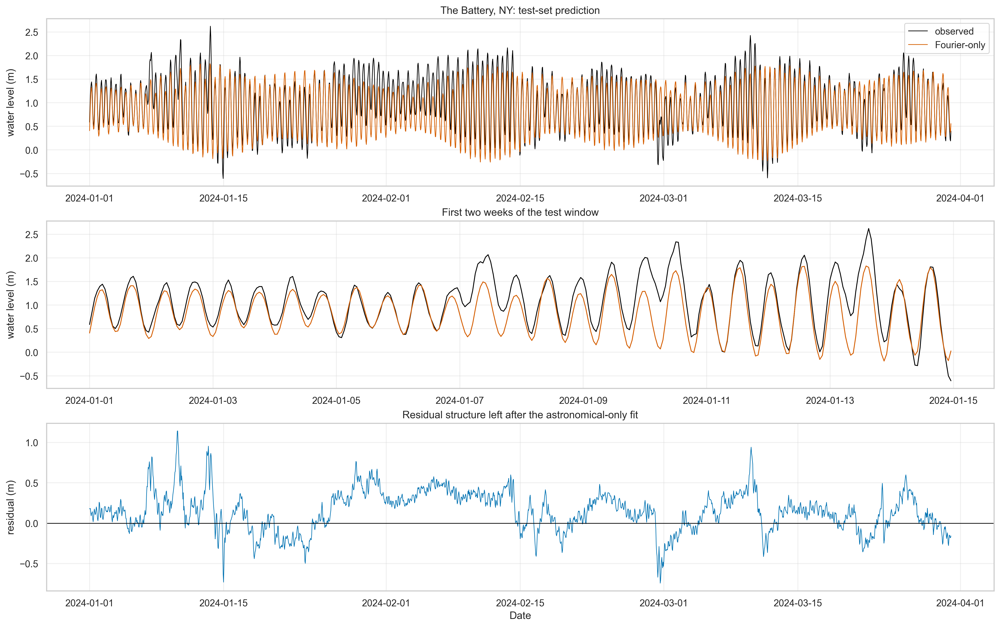

,rmse,mae,mape,r2
train,0.1571,0.1118,29.3552,0.9106
test,0.2859,0.2301,40.4504,0.7135


In [7]:
multi_periodic = _make_multi_periodic(samples_per_hour)
fourier_X_train = pd.DataFrame(index=df_train.index)
fourier_X_test = pd.DataFrame(index=df_test.index)

fourier_est = TsgamEstimator(
    config=TsgamEstimatorConfig(
        multi_periodic_config=multi_periodic,
        exog_config=None,
        solver_config=TsgamSolverConfig(solver=SOLVER, verbose=False),
        random_state=42,
    )
)
fourier_est.fit(fourier_X_train, y_train)

fourier_train_pred = fourier_est.predict(fourier_X_train)
fourier_test_pred = fourier_est.predict(fourier_X_test)
fourier_residual_train = y_train - fourier_train_pred
fourier_residual_test = y_test - fourier_test_pred

fourier_metrics = pd.DataFrame(
    {
        "train": _tidal_metrics(y_train, fourier_train_pred),
        "test": _tidal_metrics(y_test, fourier_test_pred),
    }
).T

fig, axes = plt.subplots(3, 1, figsize=(16, 10), constrained_layout=True)
axes[0].plot(df_test.index, y_test, color="black", linewidth=0.8, label="observed")
axes[0].plot(df_test.index, fourier_test_pred, color="#D55E00", linewidth=0.8, label="Fourier-only")
axes[0].set_title(f"{station_meta['name']}: test-set prediction")
axes[0].set_ylabel("water level (m)")
axes[0].legend(loc="upper right")

detail_n = min(len(df_test), 14 * 24 * samples_per_hour)
axes[1].plot(df_test.index[:detail_n], y_test[:detail_n], color="black", linewidth=1.0)
axes[1].plot(df_test.index[:detail_n], fourier_test_pred[:detail_n], color="#D55E00", linewidth=1.0)
axes[1].set_title("First two weeks of the test window")
axes[1].set_ylabel("water level (m)")

axes[2].plot(df_test.index, fourier_residual_test, color="#0072B2", linewidth=0.7)
axes[2].axhline(0.0, color="black", linewidth=0.8)
axes[2].set_title("Residual structure left after the astronomical-only fit")
axes[2].set_ylabel("residual (m)")
axes[2].set_xlabel("Date")
plt.show()

fourier_metrics

## Fourier-Only Residual Periodogram

Use the Fourier-only residual spectrum to look for periodic structure that the astronomical basis still misses. The peak table separates the nearest fundamental period from the closest harmonic candidates so low-frequency peaks are not over-interpreted as base constituents.


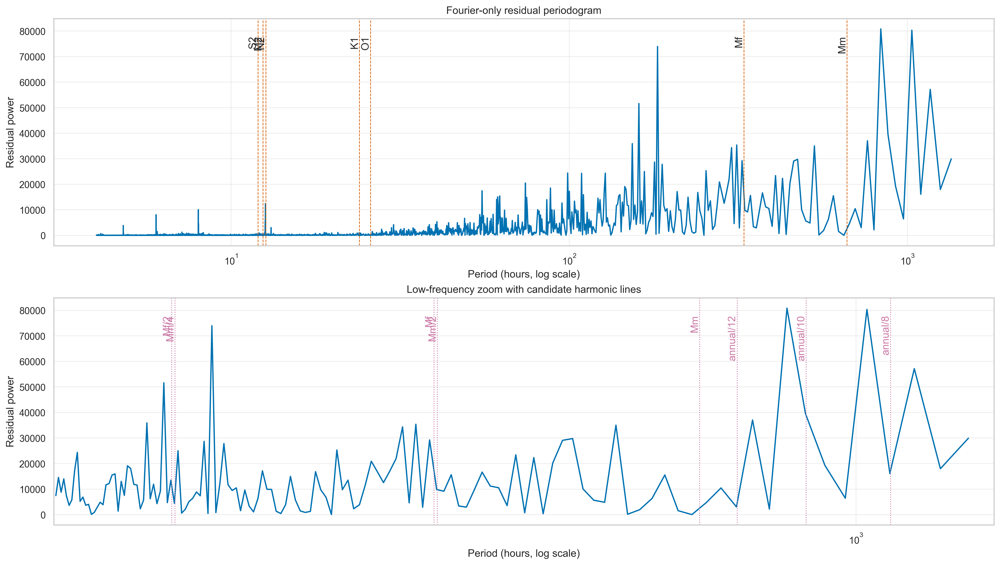

,period_hours,power,nearest_fundamental_period,delta_to_fundamental_hours,closest_harmonic_candidates,delta_to_nearest_harmonic_hours
0,833.1905,"80,840.6545",Mm,171.8805,"annual/11, annual/10, annual/12",36.2977
1,"1,029.2353","80,342.2682",Mm,367.9253,"annual/9, annual/8, annual/10",55.2553
2,182.2604,"73,970.8143",Mf,-145.5995,"Mm/4, Mf/2, Mm/3",16.9329
3,"1,166.4667","57,157.2114",Mm,505.1567,"annual/8, annual/7, annual/9",70.7392
4,160.5229,"51,613.8382",O1,134.7036,"Mf/2, Mm/4, Mf/3",-3.4070
5,874.8500,"39,581.5998",Mm,213.5400,"annual/10, annual/11, annual/9",-1.7320
6,760.7391,"37,040.8917",Mm,99.4291,"annual/12, annual/11, Mm",30.2541
7,153.4825,"35,921.6562",O1,127.6631,"Mf/2, Mm/4, Mf/3",-10.4475


In [8]:
residual_periodogram_max_hours = 24.0 * 60.0
fourier_residual_spectrum = compute_periodogram(
    df_train.index,
    fourier_residual_train,
    min_period_hours=4.0,
    max_period_hours=residual_periodogram_max_hours,
)

fundamental_constituents = dict(TIDAL_CONSTITUENT_PERIODS_HOURS)
base_harmonics = dict(TIDAL_CONSTITUENT_HARMONICS)
harmonic_candidate_rows = []
for label, period_hours in fundamental_constituents.items():
    max_harmonic = 12 if label == "annual" else max(4, base_harmonics.get(label, 1))
    harmonic_candidate_rows.append(
        {
            "candidate": label,
            "period_hours": period_hours,
            "kind": "fundamental",
        }
    )
    for harmonic in range(2, max_harmonic + 1):
        harmonic_candidate_rows.append(
            {
                "candidate": f"{label}/{harmonic}",
                "period_hours": period_hours / harmonic,
                "kind": "harmonic",
            }
        )
harmonic_candidates = pd.DataFrame(harmonic_candidate_rows)
harmonic_candidates = harmonic_candidates[
    harmonic_candidates["period_hours"].between(4.0, residual_periodogram_max_hours)
].reset_index(drop=True)
selected_low_frequency_candidates = [
    "Mf/2",
    "Mf",
    "Mm/4",
    "Mm/2",
    "Mm",
    "annual/8",
    "annual/10",
    "annual/12",
]
selected_harmonic_lines = harmonic_candidates[
    harmonic_candidates["candidate"].isin(selected_low_frequency_candidates)
].copy()


def summarize_periodogram_peaks(spectrum: pd.DataFrame, top_n: int = 8) -> pd.DataFrame:
    selected_rows: list[dict[str, float | str]] = []
    selected_periods: list[float] = []
    ordered = spectrum.sort_values("power", ascending=False)
    for row in ordered.itertuples(index=False):
        period_hours = float(row.period_hours)
        spacing = max(0.5, 0.03 * period_hours)
        if any(abs(period_hours - prev) < spacing for prev in selected_periods):
            continue
        nearest_name, nearest_period = min(
            fundamental_constituents.items(),
            key=lambda item: abs(period_hours - item[1]),
        )
        harmonic_distances = (harmonic_candidates["period_hours"] - period_hours).abs()
        nearest_harmonic = harmonic_candidates.iloc[harmonic_distances.idxmin()]
        closest_harmonics = harmonic_candidates.iloc[
            harmonic_distances.nsmallest(3).index
        ]["candidate"].tolist()
        closest_harmonics_label = ", ".join(closest_harmonics)
        selected_rows.append(
            {
                "period_hours": period_hours,
                "power": float(row.power),
                "nearest_fundamental_period": nearest_name,
                "delta_to_fundamental_hours": period_hours - nearest_period,
                "closest_harmonic_candidates": closest_harmonics_label,
                "delta_to_nearest_harmonic_hours": period_hours - float(nearest_harmonic["period_hours"]),
            }
        )
        selected_periods.append(period_hours)
        if len(selected_rows) >= top_n:
            break
    return pd.DataFrame(selected_rows)


fig, axes = plt.subplots(2, 1, figsize=(16, 9), constrained_layout=True)
axes[0].plot(
    fourier_residual_spectrum["period_hours"],
    fourier_residual_spectrum["power"],
    color="#0072B2",
)
for label, period_hours in fundamental_constituents.items():
    if fourier_residual_spectrum["period_hours"].min() <= period_hours <= fourier_residual_spectrum["period_hours"].max():
        axes[0].axvline(period_hours, color="#D55E00", linestyle="--", linewidth=0.8)
        axes[0].text(
            period_hours,
            axes[0].get_ylim()[1] * 0.92,
            label,
            rotation=90,
            va="top",
            ha="right",
        )
axes[0].set_xscale("log")
axes[0].set_title("Fourier-only residual periodogram")
axes[0].set_xlabel("Period (hours, log scale)")
axes[0].set_ylabel("Residual power")

low_frequency_mask = fourier_residual_spectrum["period_hours"].between(120.0, residual_periodogram_max_hours)
axes[1].plot(
    fourier_residual_spectrum.loc[low_frequency_mask, "period_hours"],
    fourier_residual_spectrum.loc[low_frequency_mask, "power"],
    color="#0072B2",
)
for row in selected_harmonic_lines.itertuples(index=False):
    axes[1].axvline(row.period_hours, color="#CC79A7", linestyle=":", linewidth=1.0)
    axes[1].text(
        row.period_hours,
        axes[1].get_ylim()[1] * 0.92,
        row.candidate,
        rotation=90,
        va="top",
        ha="right",
        color="#CC79A7",
    )
axes[1].set_xscale("log")
axes[1].set_xlim(120.0, residual_periodogram_max_hours)
axes[1].set_title("Low-frequency zoom with candidate harmonic lines")
axes[1].set_xlabel("Period (hours, log scale)")
axes[1].set_ylabel("Residual power")
plt.show()

fourier_residual_peak_summary = summarize_periodogram_peaks(fourier_residual_spectrum)
fourier_residual_peak_summary


### Harmonic Sweep

A peak sitting near a harmonic line is only suggestive. This sweep keeps the residual spectra on the training window, but checks generalization with test-set RMSE. The two bands below are deliberately narrow: `150-190 h` for the `6-8 day` feature and `700-950 h` for the `30-40 day` feature. The `annual x12` case is intentionally aggressive, acting as a monthly-scale probe rather than a default recommendation.


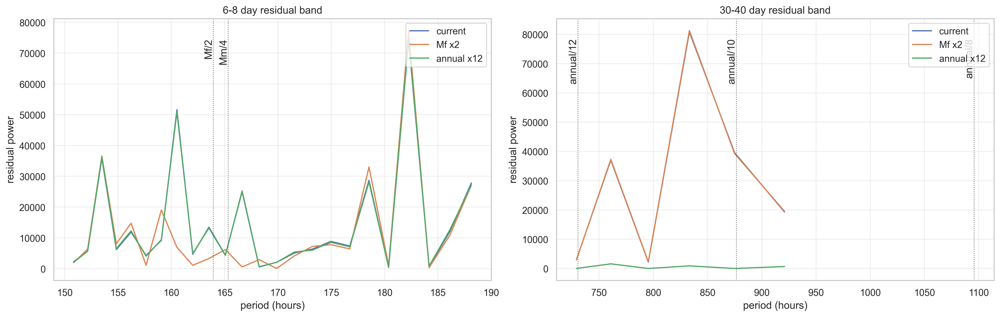

,configuration,changed_harmonics,status,test_rmse,test_r2,week_peak_hours,week_peak_power,month_peak_hours,month_peak_power
1,Mf x2,Mf=2,ok,0.2853,0.7146,182.2604,"77,372.6176",833.1905,"81,337.9224"
0,current,baseline,ok,0.2859,0.7135,182.2604,"73,970.8143",833.1905,"80,840.6545"
2,annual x12,annual=12,ok,0.2969,0.6909,182.2604,"74,583.9603",760.7391,"1,583.3291"


In [9]:
def extract_window_peak(
    spectrum: pd.DataFrame,
    lower_hours: float,
    upper_hours: float,
) -> tuple[float, float]:
    window = spectrum[spectrum["period_hours"].between(lower_hours, upper_hours)]
    if window.empty:
        return np.nan, np.nan
    peak = window.loc[window["power"].idxmax()]
    return float(peak["period_hours"]), float(peak["power"])


harmonic_sweep_specs = {
    "current": dict(base_harmonics),
    "Mf x2": {**base_harmonics, "Mf": 2},
    "annual x12": {**base_harmonics, "annual": 12},
}
harmonic_sweep_results: list[dict[str, float | str]] = []
harmonic_sweep_spectra: dict[str, pd.DataFrame] = {}
for config_name, harmonic_map in harmonic_sweep_specs.items():
    changed_terms = [
        f"{label}={harmonic_map[label]}"
        for label in TIDAL_COMPONENT_LABELS
        if harmonic_map[label] != base_harmonics[label]
    ]
    changed_harmonics = ", ".join(changed_terms) if changed_terms else "baseline"
    try:
        candidate_multi_periodic = TsgamMultiPeriodicConfig(
            num_harmonics=[harmonic_map[label] for label in TIDAL_COMPONENT_LABELS],
            periods=[
                fundamental_constituents[label] * samples_per_hour
                for label in TIDAL_COMPONENT_LABELS
            ],
            reg_weight=multi_periodic.reg_weight,
        )
        candidate_est = TsgamEstimator(
            config=TsgamEstimatorConfig(
                multi_periodic_config=candidate_multi_periodic,
                exog_config=None,
                solver_config=TsgamSolverConfig(solver=SOLVER, verbose=False),
                random_state=42,
            )
        )
        candidate_est.fit(fourier_X_train, y_train)
        candidate_train_pred = candidate_est.predict(fourier_X_train)
        candidate_test_pred = candidate_est.predict(fourier_X_test)
        candidate_spectrum = compute_periodogram(
            df_train.index,
            y_train - candidate_train_pred,
            min_period_hours=4.0,
            max_period_hours=residual_periodogram_max_hours,
        )
        harmonic_sweep_spectra[config_name] = candidate_spectrum
        week_peak_hours, week_peak_power = extract_window_peak(candidate_spectrum, 150.0, 190.0)
        month_peak_hours, month_peak_power = extract_window_peak(candidate_spectrum, 700.0, 950.0)
        candidate_metrics = _tidal_metrics(y_test, candidate_test_pred)
        harmonic_sweep_results.append(
            {
                "configuration": config_name,
                "changed_harmonics": changed_harmonics,
                "status": "ok",
                "test_rmse": candidate_metrics["rmse"],
                "test_r2": candidate_metrics["r2"],
                "week_peak_hours": week_peak_hours,
                "week_peak_power": week_peak_power,
                "month_peak_hours": month_peak_hours,
                "month_peak_power": month_peak_power,
            }
        )
    except Exception as exc:
        harmonic_sweep_results.append(
            {
                "configuration": config_name,
                "changed_harmonics": changed_harmonics,
                "status": f"failed: {type(exc).__name__}",
                "test_rmse": np.nan,
                "test_r2": np.nan,
                "week_peak_hours": np.nan,
                "week_peak_power": np.nan,
                "month_peak_hours": np.nan,
                "month_peak_power": np.nan,
            }
        )

if harmonic_sweep_spectra:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
    window_specs = [
        (axes[0], 150.0, 190.0, "6-8 day residual band", ["Mf/2", "Mm/4"]),
        (axes[1], 700.0, 950.0, "30-40 day residual band", ["annual/12", "annual/10", "annual/8"]),
    ]
    for ax, lower_hours, upper_hours, title, candidate_labels in window_specs:
        for config_name, spectrum in harmonic_sweep_spectra.items():
            window = spectrum[spectrum["period_hours"].between(lower_hours, upper_hours)]
            ax.plot(window["period_hours"], window["power"], linewidth=1.4, label=config_name)
        for label in candidate_labels:
            candidate = harmonic_candidates[harmonic_candidates["candidate"] == label]
            if not candidate.empty:
                period_hours = float(candidate.iloc[0]["period_hours"])
                ax.axvline(period_hours, color="#666666", linestyle=":", linewidth=0.9)
                ax.text(period_hours, ax.get_ylim()[1] * 0.92, label, rotation=90, va="top", ha="right")
        ax.set_title(title)
        ax.set_xlabel("period (hours)")
        ax.set_ylabel("residual power")
        ax.legend(loc="upper right")
    plt.show()

harmonic_sweep_table = pd.DataFrame(harmonic_sweep_results).sort_values("test_rmse", na_position="last")
harmonic_sweep_table


## Component Decomposition

Decompose the fitted Fourier contribution into the named tidal scales and separate the cross-term energy induced by the full multi-period basis.

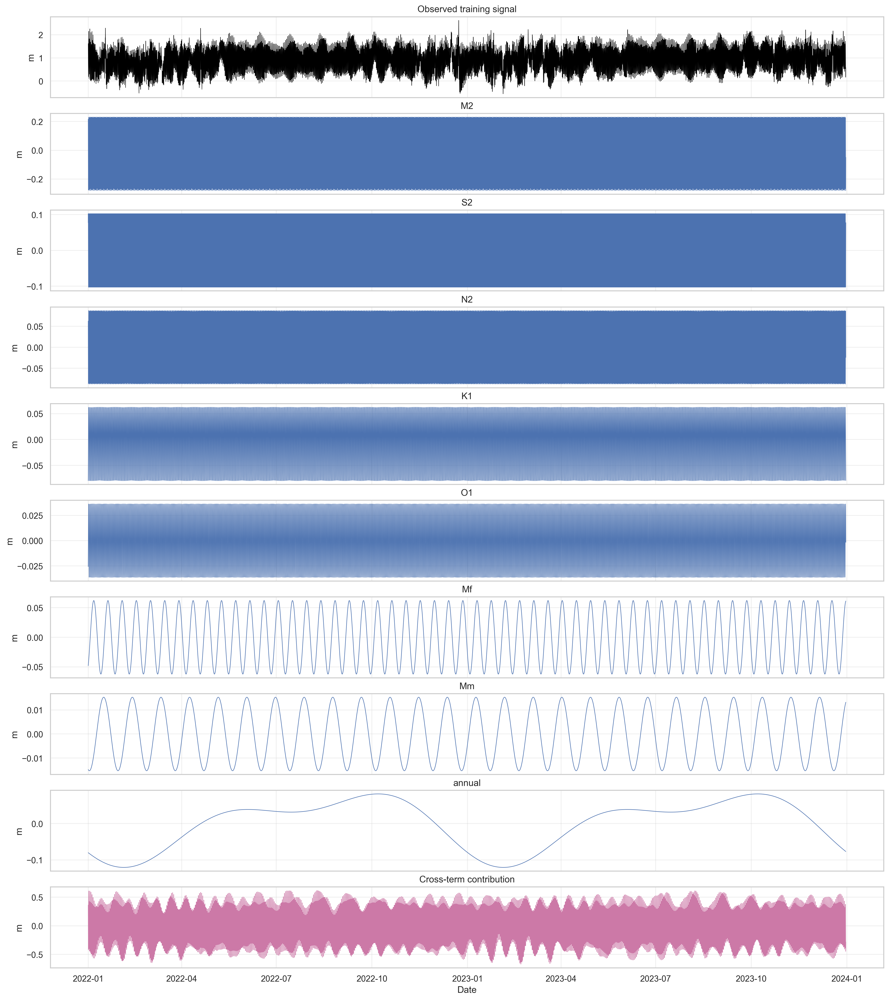

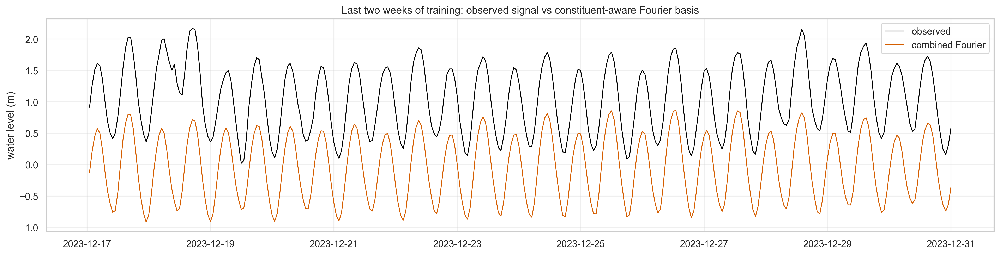

,rms_amplitude
cross_terms,0.3011
M2,0.1788
S2,0.0743
annual,0.0644
N2,0.0619
K1,0.0485
Mf,0.0439
O1,0.0257
Mm,0.0108


In [10]:
component_labels = list(TIDAL_COMPONENT_LABELS)
component_dict = extract_fourier_components(fourier_est, labels=component_labels)
main_component_names = [
    name for name in component_labels if name in component_dict
]
cross_component_names = [
    name for name in component_dict if "_x_" in name
]
if cross_component_names:
    cross_component = np.sum(
        [component_dict[name] for name in cross_component_names],
        axis=0,
    )
else:
    cross_component = np.zeros_like(component_dict["combined"])

component_rms = pd.DataFrame(
    {
        "rms_amplitude": {
            **{name: float(np.sqrt(np.mean(component_dict[name] ** 2))) for name in main_component_names},
            "cross_terms": float(np.sqrt(np.mean(cross_component ** 2))),
        }
    }
).sort_values("rms_amplitude", ascending=False)

n_rows = len(main_component_names) + 2
fig, axes = plt.subplots(
    n_rows,
    1,
    figsize=(16, max(12, 1.8 * n_rows)),
    sharex=True,
    constrained_layout=True,
)
axes = np.atleast_1d(axes)
axes[0].plot(df_train.index, y_train, color="black", linewidth=0.5)
axes[0].set_title("Observed training signal")
axes[0].set_ylabel("m")
for ax, name in zip(axes[1:-1], main_component_names, strict=True):
    ax.plot(df_train.index, component_dict[name], linewidth=0.7)
    ax.set_title(name)
    ax.set_ylabel("m")
axes[-1].plot(df_train.index, cross_component, color="#CC79A7", linewidth=0.7)
axes[-1].set_title("Cross-term contribution")
axes[-1].set_ylabel("m")
axes[-1].set_xlabel("Date")
plt.show()

zoom_n = min(len(df_train), 14 * 24 * samples_per_hour)
zoom_index = df_train.index[-zoom_n:]
fig, ax = plt.subplots(figsize=(16, 4), constrained_layout=True)
ax.plot(zoom_index, y_train[-zoom_n:], color="black", linewidth=1.0, label="observed")
ax.plot(
    zoom_index,
    component_dict["combined"][-zoom_n:],
    color="#D55E00",
    linewidth=1.0,
    label="combined Fourier",
)
ax.set_title("Last two weeks of training: observed signal vs constituent-aware Fourier basis")
ax.set_ylabel("water level (m)")
ax.legend(loc="upper right")
plt.show()

component_rms


## Adding Meteorological Regressors

Now keep the astronomical basis fixed and ask which weather variables reduce the non-tidal residual. The regressor workflow mirrors the analysis done in the tidal run script: select high-availability channels, standardize them on the training window, and fit an incremental ablation sequence.

In [11]:
all_regressor_candidates = ["pressure", "water_temp", "wind_u", "wind_v", "air_temp"]
available_regressors = [
    c for c in all_regressor_candidates
    if c in df.columns and df_train[c].notna().mean() > 0.5
]
regressor_checkboxes = {
    col: widgets.Checkbox(value=True, description=col, indent=False,
                          layout=widgets.Layout(width="140px"))
    for col in available_regressors
}
causal_only_toggle = widgets.Checkbox(
    value=False,
    description="Causal only (drop leading lags)",
    indent=False,
    layout=widgets.Layout(width="280px"),
    style={"description_width": "initial"},
)
display(widgets.VBox([
    widgets.HBox(
        [widgets.Label("Regressors to include:")] + list(regressor_checkboxes.values()),
        layout=widgets.Layout(flex_flow="row wrap"),
    ),
    widgets.HBox([causal_only_toggle]),
]))


Causal mode: stripped leading (positive) lags from all spline configs.
  pressure: lags = [-2, -1, 0]
  water_temp: lags = [0]
  wind_u: lags = [-1, 0]
  wind_v: lags = [-1, 0]
  air_temp: lags = [0]


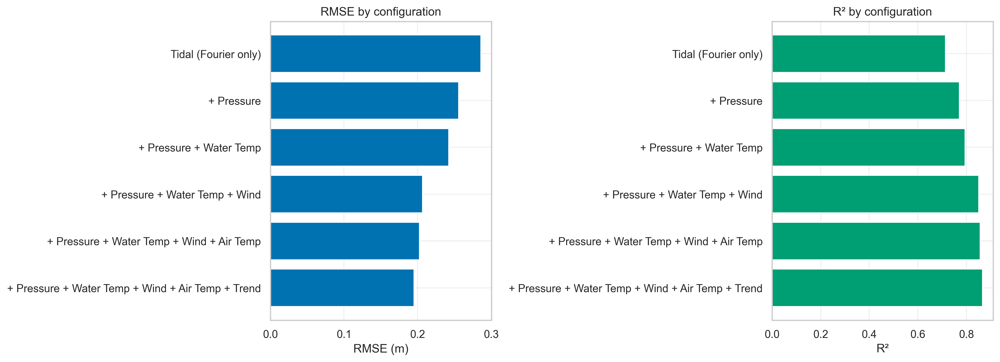

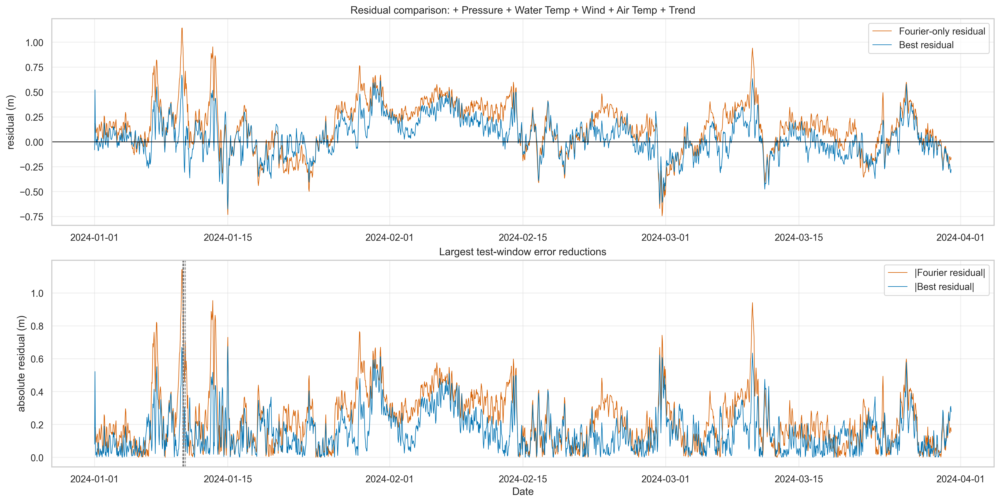

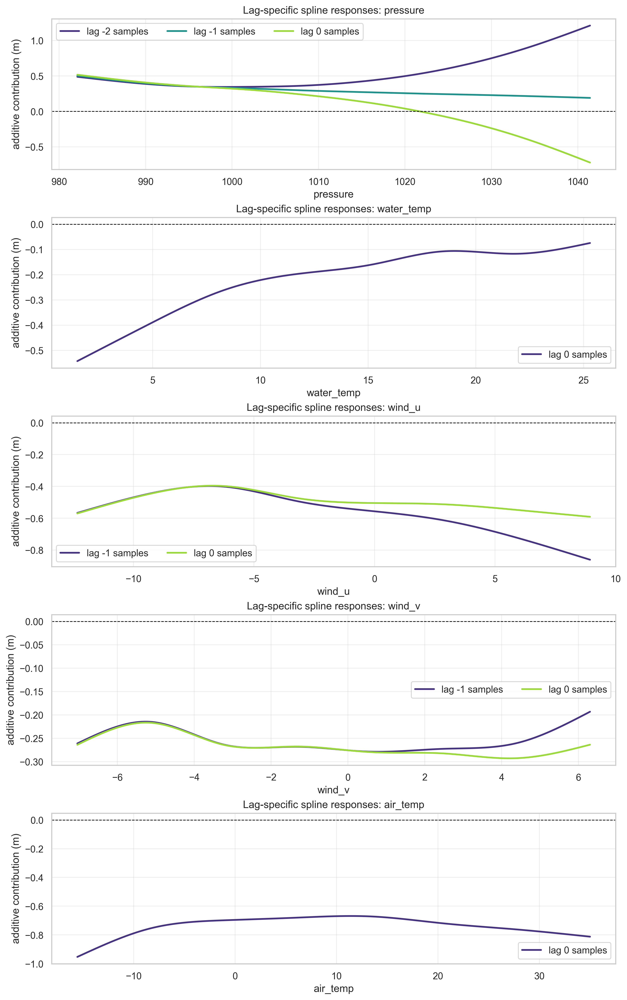

(                                       configuration   rmse    mae     r2  \
 0                               Tidal (Fourier only) 0.2859 0.2301 0.7135   
 1                                         + Pressure 0.2558 0.2034 0.7706   
 2                            + Pressure + Water Temp 0.2423 0.1901 0.7942   
 3                     + Pressure + Water Temp + Wind 0.2067 0.1617 0.8502   
 4          + Pressure + Water Temp + Wind + Air Temp 0.2025 0.1583 0.8562   
 5  + Pressure + Water Temp + Wind + Air Temp + Trend 0.1951 0.1528 0.8666   
 
    rmse_improvement_pct  
 0                0.0000  
 1               10.5183  
 2               15.2462  
 3               27.7021  
 4               29.1615  
 5               31.7653  ,
             timestamp  baseline_abs_error  best_abs_error  error_reduction
 0 2024-01-10 08:00:00              0.7421          0.0646           0.6774
 1 2024-01-10 13:00:00              0.7102          0.0560           0.6542
 2 2024-01-10 07:00:00            

In [16]:
regressor_candidates = [
    col for col, cb in regressor_checkboxes.items() if cb.value
]
wl_mask_train = df_train["water_level"].notna()
wl_mask_test = df_test["water_level"].notna()
regressor_cols = [
    column
    for column in regressor_candidates
    if column in df.columns
    and df_train.loc[wl_mask_train, column].notna().mean() > 0.99
    and df_test.loc[wl_mask_test, column].notna().mean() > 0.99
]
for column in regressor_cols:
    df_train[column] = df_train[column].interpolate(limit_direction="both")
    df_test[column] = df_test[column].interpolate(limit_direction="both")

reg_means = df_train[regressor_cols].mean() if regressor_cols else pd.Series(dtype=float)
reg_stds = df_train[regressor_cols].std().replace(0, 1) if regressor_cols else pd.Series(dtype=float)
X_train_std = (
    (df_train[regressor_cols] - reg_means) / reg_stds
    if regressor_cols
    else pd.DataFrame(index=df_train.index)
)
X_test_std = (
    (df_test[regressor_cols] - reg_means) / reg_stds
    if regressor_cols
    else pd.DataFrame(index=df_test.index)
)

spline_configs, default_spline = _make_spline_configs(samples_per_hour)
if causal_only_toggle.value:
    from tsgam_estimator import TsgamSplineConfig as _SC
    spline_configs = {
        var: _SC(
            n_knots=cfg.n_knots,
            lags=[lag for lag in cfg.lags if lag <= 0],
            reg_weight=cfg.reg_weight,
            diff_reg_weight=cfg.diff_reg_weight,
        )
        for var, cfg in spline_configs.items()
    }
    default_spline = _SC(
        n_knots=default_spline.n_knots,
        lags=[lag for lag in default_spline.lags if lag <= 0],
        reg_weight=default_spline.reg_weight,
        diff_reg_weight=default_spline.diff_reg_weight,
    )
    print("Causal mode: stripped leading (positive) lags from all spline configs.")
    for var, cfg in spline_configs.items():
        if var in regressor_cols:
            print(f"  {var}: lags = {cfg.lags}")
ablation_configs = _build_tidal_configs(
    X_train_std,
    y_train,
    X_test_std,
    y_test,
    set(regressor_cols),
    multi_periodic=multi_periodic,
    spline_configs=spline_configs,
    default_spline=default_spline,
    solver=SOLVER,
)
for cfg in ablation_configs:
    if cfg.get("trend_config") is not None:
        cfg["trend_config"].grouping = 24.0 * samples_per_hour
ablation_results = [_fit_single_tidal(cfg) for cfg in ablation_configs]

ablation_table = pd.DataFrame(
    [
        {
            "configuration": result["name"],
            "rmse": result["rmse"],
            "mae": result["mae"],
            "r2": result["r2"],
        }
        for result in ablation_results
        if result["y_pred"] is not None
    ]
)
baseline_rmse = ablation_table.loc[
    ablation_table["configuration"] == "Tidal (Fourier only)",
    "rmse",
].iloc[0]
ablation_table["rmse_improvement_pct"] = (
    (baseline_rmse - ablation_table["rmse"]) / baseline_rmse * 100
)

valid_results = [result for result in ablation_results if result["y_pred"] is not None]
best_result = min(valid_results, key=lambda result: result["rmse"])
best_cfg = next(cfg for cfg in ablation_configs if cfg["name"] == best_result["name"])
best_variable_names = list(best_cfg["variable_names"])
best_trend_config = best_cfg.get("trend_config")
best_exog_config = [
    spline_configs.get(name, default_spline) for name in best_variable_names
] or None

best_est = TsgamEstimator(
    config=TsgamEstimatorConfig(
        multi_periodic_config=multi_periodic,
        exog_config=best_exog_config,
        trend_config=best_trend_config,
        solver_config=TsgamSolverConfig(solver=SOLVER, verbose=False),
        random_state=42,
    )
)
best_est.fit(best_cfg["X_train"], y_train)
best_train_pred = best_est.predict(best_cfg["X_train"])
best_test_pred = best_est.predict(best_cfg["X_test"])
best_residual_test = y_test - best_test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
plot_table = ablation_table.sort_values("rmse", ascending=True)
axes[0].barh(plot_table["configuration"], plot_table["rmse"], color="#0072B2")
axes[0].set_title("RMSE by configuration")
axes[0].set_xlabel("RMSE (m)")
axes[1].barh(plot_table["configuration"], plot_table["r2"], color="#009E73")
axes[1].set_title("R² by configuration")
axes[1].set_xlabel("R²")
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(16, 8), constrained_layout=True)
axes[0].plot(df_test.index, fourier_residual_test, color="#D55E00", linewidth=0.7, label="Fourier-only residual")
axes[0].plot(df_test.index, best_residual_test, color="#0072B2", linewidth=0.7, label="Best residual")
axes[0].axhline(0.0, color="black", linewidth=0.8)
axes[0].set_title(f"Residual comparison: {best_result['name']}")
axes[0].set_ylabel("residual (m)")
axes[0].legend(loc="upper right")

error_reduction = np.abs(fourier_residual_test) - np.abs(best_residual_test)
top_event_idx = np.argsort(error_reduction)[-5:][::-1]
event_summary = pd.DataFrame(
    {
        "timestamp": df_test.index[top_event_idx],
        "baseline_abs_error": np.abs(fourier_residual_test[top_event_idx]),
        "best_abs_error": np.abs(best_residual_test[top_event_idx]),
        "error_reduction": error_reduction[top_event_idx],
    }
).sort_values("error_reduction", ascending=False)
axes[1].plot(df_test.index, np.abs(fourier_residual_test), color="#D55E00", linewidth=0.7, label="|Fourier residual|")
axes[1].plot(df_test.index, np.abs(best_residual_test), color="#0072B2", linewidth=0.7, label="|Best residual|")
for timestamp in event_summary["timestamp"]:
    axes[1].axvline(timestamp, color="0.5", linestyle="--", linewidth=0.8)
axes[1].set_title("Largest test-window error reductions")
axes[1].set_ylabel("absolute residual (m)")
axes[1].set_xlabel("Date")
axes[1].legend(loc="upper right")
plt.show()

if best_variable_names:
    fig, axes = plt.subplots(
        len(best_variable_names),
        1,
        figsize=(10, 3.2 * len(best_variable_names)),
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes)
    for var_idx, (ax, variable_name) in enumerate(zip(axes, best_variable_names, strict=True)):
        coef_matrix = best_est.variables_[f"exog_coef_{var_idx}"].value
        knots = best_est.exog_knots_[var_idx]
        lag_list = list(best_exog_config[var_idx].lags)
        x_values = best_cfg["X_train"][variable_name].to_numpy()
        x_smooth = np.linspace(x_values.min(), x_values.max(), 200)
        h_smooth = best_est._make_H(x_smooth, knots, include_offset=False)
        raw_x_smooth = x_smooth * reg_stds[variable_name] + reg_means[variable_name]
        colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(lag_list)))
        for color, lag_idx, lag in zip(colors, range(len(lag_list)), lag_list, strict=True):
            response_smooth = h_smooth @ coef_matrix[:, lag_idx]
            ax.plot(
                raw_x_smooth,
                response_smooth,
                color=color,
                linewidth=2,
                label=f"lag {lag} samples",
            )
        ax.axhline(0.0, color="black", linewidth=0.8, linestyle="--")
        ax.set_title(f"Lag-specific spline responses: {variable_name}")
        ax.set_xlabel(variable_name)
        ax.set_ylabel("additive contribution (m)")
        ax.legend(loc="best", ncol=min(3, len(lag_list)))
    plt.show()

ablation_table, event_summary

## Trend, Outliers, and Uncertainty

Use the best regressor set as the base specification and then inspect three higher-level behaviors: slow sea-level drift, anomalous event periods, and stochastic forecast spread.

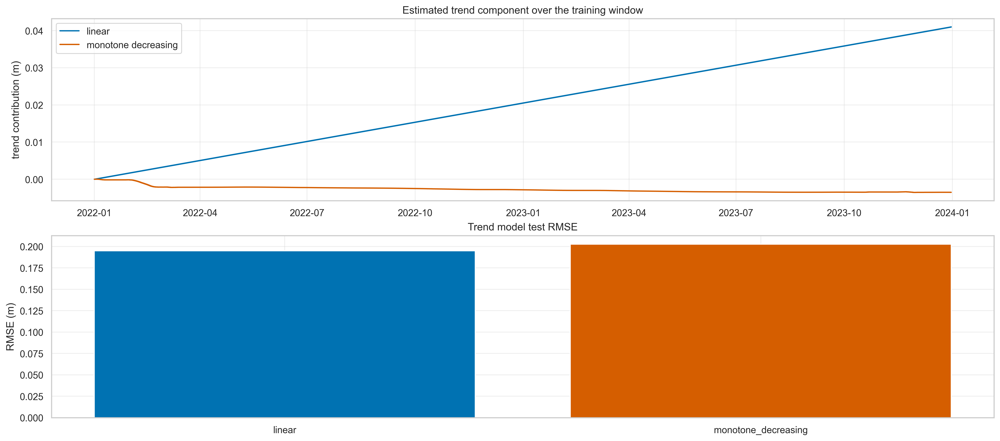

No meaningful outlier signal was detected for this station/window; the sweep stayed in the numerical-noise range.


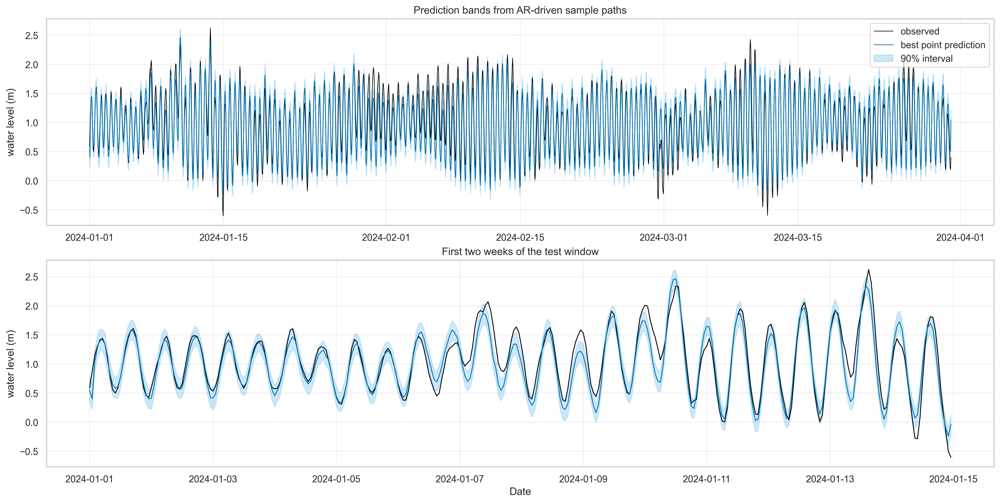

,period_samples,period_hours,reg_weight,nonzero_gt_1e4,nonzero_gt_1e3,max_abs_outlier,has_signal
13,12.0000,12.0000,0.0500,0,0,0.0000,False
5,24.0000,24.0000,0.1000,0,0,0.0000,False
6,24.0000,24.0000,0.0500,0,0,0.0000,False
20,6.0000,6.0000,0.0500,0,0,0.0000,False
9,12.0000,12.0000,1.0000,0,0,0.0000,False
8,12.0000,12.0000,2.0000,0,0,0.0000,False
7,12.0000,12.0000,5.0000,0,0,0.0000,False
10,12.0000,12.0000,0.5000,0,0,0.0000,False
11,12.0000,12.0000,0.2500,0,0,0.0000,False
12,12.0000,12.0000,0.1000,0,0,0.0000,False


In [13]:
trend_models = {}
trend_metrics = {}
trend_model_specs = [
    ("linear", TrendType.LINEAR),
    ("monotone_decreasing", TrendType.NONLINEAR),
]
for trend_label, trend_type in trend_model_specs:
    est = TsgamEstimator(
        config=TsgamEstimatorConfig(
            multi_periodic_config=multi_periodic,
            exog_config=best_exog_config,
            trend_config=TsgamTrendConfig(
                trend_type=trend_type,
                grouping=24.0 * samples_per_hour,
            ),
            solver_config=TsgamSolverConfig(solver=SOLVER, verbose=False),
            random_state=42,
        )
    )
    est.fit(best_cfg["X_train"], y_train)
    trend_models[trend_label] = est
    trend_metrics[trend_label] = _tidal_metrics(y_test, est.predict(best_cfg["X_test"]))

linear_trend = trend_models["linear"].trend_T_matrix_ @ trend_models["linear"].variables_["trend"].value
monotone_trend = trend_models["monotone_decreasing"].trend_T_matrix_ @ trend_models["monotone_decreasing"].variables_["trend"].value

fig, axes = plt.subplots(2, 1, figsize=(16, 7), constrained_layout=True)
axes[0].plot(df_train.index, linear_trend, color="#0072B2", label="linear")
axes[0].plot(df_train.index, monotone_trend, color="#D55E00", label="monotone decreasing")
axes[0].set_title("Estimated trend component over the training window")
axes[0].set_ylabel("trend contribution (m)")
axes[0].legend(loc="upper left")

trend_compare = pd.DataFrame(trend_metrics).T[["rmse", "mae", "r2"]]
axes[1].bar(trend_compare.index, trend_compare["rmse"], color=["#0072B2", "#D55E00"])
axes[1].set_title("Trend model test RMSE")
axes[1].set_ylabel("RMSE (m)")
plt.show()

outlier_models = {}
outlier_grid_rows = []
for period_samples in (24.0 * samples_per_hour, 12.0 * samples_per_hour, 6.0 * samples_per_hour):
    for reg_weight in (5.0, 2.0, 1.0, 0.5, 0.25, 0.1, 0.05):
        est = TsgamEstimator(
            config=TsgamEstimatorConfig(
                multi_periodic_config=multi_periodic,
                exog_config=best_exog_config,
                trend_config=best_trend_config,
                outlier_config=TsgamOutlierConfig(
                    reg_weight=reg_weight,
                    period_hours=period_samples,
                ),
                solver_config=TsgamSolverConfig(solver=SOLVER, verbose=False),
                random_state=42,
            )
        )
        est.fit(best_cfg["X_train"], y_train)
        outlier_values = est.variables_["outlier"].value
        outlier_models[(period_samples, reg_weight)] = est
        outlier_grid_rows.append(
            {
                "period_samples": period_samples,
                "period_hours": period_samples / samples_per_hour,
                "reg_weight": reg_weight,
                "nonzero_gt_1e4": int(np.sum(np.abs(outlier_values) > 1e-4)),
                "nonzero_gt_1e3": int(np.sum(np.abs(outlier_values) > 1e-3)),
                "max_abs_outlier": float(np.max(np.abs(outlier_values))),
            }
        )
outlier_grid = pd.DataFrame(outlier_grid_rows)
outlier_grid["has_signal"] = (
    (outlier_grid["max_abs_outlier"] >= 1e-4)
    & (outlier_grid["nonzero_gt_1e4"] > 0)
)
outlier_signal_summary = (
    outlier_grid.groupby("period_hours")["has_signal"]
    .sum()
    .rename("signal_config_count")
    .to_frame()
)
meaningful_outlier_signal = outlier_signal_summary["signal_config_count"].max() >= 2
if meaningful_outlier_signal:
    outlier_choice = outlier_grid[outlier_grid["has_signal"]].sort_values(
        ["max_abs_outlier", "nonzero_gt_1e4", "nonzero_gt_1e3"],
        ascending=False,
    ).iloc[0]
else:
    outlier_choice = outlier_grid.sort_values(
        ["max_abs_outlier", "nonzero_gt_1e4", "nonzero_gt_1e3"],
        ascending=False,
    ).iloc[0]
outlier_est = outlier_models[(outlier_choice["period_samples"], outlier_choice["reg_weight"])]
outlier_values = outlier_est.variables_["outlier"].value
outlier_component = outlier_est.outlier_T_matrix_ @ outlier_values
outlier_period_ids = outlier_est.outlier_T_matrix_.argmax(axis=1)
outlier_dates = pd.Index(
    [
        df_train.index[np.where(outlier_period_ids == period_id)[0][0]]
        for period_id in range(len(outlier_values))
    ]
)
outlier_summary = pd.DataFrame(
    {
        "timestamp": outlier_dates,
        "outlier": outlier_values,
        "abs_outlier": np.abs(outlier_values),
    }
).sort_values("abs_outlier", ascending=False)
if meaningful_outlier_signal:
    fig, axes = plt.subplots(2, 1, figsize=(16, 8), constrained_layout=True)
    axes[0].stem(outlier_summary["timestamp"].head(25), outlier_summary["outlier"].head(25))
    axes[0].set_title(
        "Largest detected outlier periods "
        f"(period={outlier_choice['period_hours']} h, weight={outlier_choice['reg_weight']})"
    )
    axes[0].set_ylabel("outlier term (m)")
    axes[1].plot(df_train.index, y_train, color="black", linewidth=0.7, label="observed")
    axes[1].plot(df_train.index, outlier_component, color="#CC79A7", linewidth=0.9, label="outlier component")
    for timestamp in outlier_summary["timestamp"].head(10):
        axes[1].axvline(timestamp, color="0.6", linestyle="--", linewidth=0.8)
    axes[1].set_title("Outlier timing against the training signal")
    axes[1].set_ylabel("water level / outlier (m)")
    axes[1].legend(loc="upper right")
    plt.show()
else:
    print(
        "No meaningful outlier signal was detected for this station/window; "
        "the sweep stayed in the numerical-noise range."
    )

try:
    interval_est = TsgamEstimator(
        config=TsgamEstimatorConfig(
            multi_periodic_config=multi_periodic,
            exog_config=best_exog_config,
            ar_config=TsgamArConfig(lags=list(range(1, 13))),
            trend_config=best_trend_config,
            solver_config=TsgamSolverConfig(solver=SOLVER, verbose=False),
            random_state=42,
        )
    )
    interval_est.fit(best_cfg["X_train"], y_train)
    interval_samples = interval_est.sample(best_cfg["X_test"], n_samples=200, random_state=42)
    if getattr(interval_est, "ar_coef_", None) is not None:
        interval_note = "Prediction bands from AR-driven sample paths"
    else:
        interval_note = "Prediction bands from Laplace-noise sample paths (AR fit unavailable)"
except Exception as exc:
    interval_est = best_est
    interval_samples = best_est.sample(best_cfg["X_test"], n_samples=200, random_state=42)
    interval_note = f"Fallback to independent-noise samples: {exc}"

interval_lower = np.percentile(interval_samples, 5, axis=0)
interval_upper = np.percentile(interval_samples, 95, axis=0)
zoom_n = min(len(df_test), 14 * 24 * samples_per_hour)

fig, axes = plt.subplots(2, 1, figsize=(16, 8), constrained_layout=True)
axes[0].plot(df_test.index, y_test, color="black", linewidth=0.7, label="observed")
axes[0].plot(df_test.index, best_test_pred, color="#0072B2", linewidth=0.8, label="best point prediction")
axes[0].fill_between(df_test.index, interval_lower, interval_upper, color="#56B4E9", alpha=0.3, label="90% interval")
axes[0].set_title(interval_note)
axes[0].set_ylabel("water level (m)")
axes[0].legend(loc="upper right")

axes[1].plot(df_test.index[:zoom_n], y_test[:zoom_n], color="black", linewidth=1.0)
axes[1].plot(df_test.index[:zoom_n], best_test_pred[:zoom_n], color="#0072B2", linewidth=1.0)
axes[1].fill_between(
    df_test.index[:zoom_n],
    interval_lower[:zoom_n],
    interval_upper[:zoom_n],
    color="#56B4E9",
    alpha=0.3,
)
axes[1].set_title("First two weeks of the test window")
axes[1].set_ylabel("water level (m)")
axes[1].set_xlabel("Date")
plt.show()

outlier_grid.sort_values(["max_abs_outlier", "nonzero_gt_1e4"], ascending=False).head(10)

In [ ]:
if outlier_grid is not None and not outlier_grid.empty:
    outlier_explore_output = widgets.Output()

    period_values = sorted(outlier_grid["period_hours"].unique())
    weight_values = sorted(outlier_grid["reg_weight"].unique())

    period_slider = widgets.SelectionSlider(
        options=[("%.0f h" % p, p) for p in period_values],
        value=outlier_choice["period_hours"],
        description="Period:",
        style={"description_width": "80px"},
        layout=widgets.Layout(width="400px"),
        continuous_update=False,
    )
    weight_slider = widgets.SelectionSlider(
        options=[("%.3f" % w, w) for w in weight_values],
        value=outlier_choice["reg_weight"],
        description="Reg weight:",
        style={"description_width": "80px"},
        layout=widgets.Layout(width="400px"),
        continuous_update=False,
    )

    def _update_outlier_view(*_args):
        with outlier_explore_output:
            outlier_explore_output.clear_output(wait=True)
            key = (period_slider.value * samples_per_hour, weight_slider.value)
            if key not in outlier_models:
                print(f"No model for {key}")
                return
            est = outlier_models[key]
            ov = est.variables_["outlier"].value
            oc = est.outlier_T_matrix_ @ ov
            period_ids = est.outlier_T_matrix_.argmax(axis=1)
            dates = pd.Index([
                df_train.index[np.where(period_ids == pid)[0][0]]
                for pid in range(len(ov))
            ])
            top_k = min(25, len(ov))
            order = np.argsort(np.abs(ov))[::-1][:top_k]

            fig, axes = plt.subplots(2, 1, figsize=(16, 8), constrained_layout=True)
            axes[0].stem(dates[order], ov[order])
            axes[0].set_title(
                f"Top {top_k} outlier periods  "
                f"(period={period_slider.value:.0f} h, weight={weight_slider.value:.3f})"
            )
            axes[0].set_ylabel("outlier term (m)")

            axes[1].plot(df_train.index, y_train, color="black", linewidth=0.7, label="observed")
            axes[1].plot(df_train.index, oc, color="#CC79A7", linewidth=0.9, label="outlier component")
            for ts in dates[order[:10]]:
                axes[1].axvline(ts, color="0.6", linestyle="--", linewidth=0.8)
            axes[1].set_title("Outlier timing against the training signal")
            axes[1].set_ylabel("water level / outlier (m)")
            axes[1].legend(loc="upper right")
            plt.show()

            row = outlier_grid[
                (outlier_grid["period_hours"] == period_slider.value)
                & (outlier_grid["reg_weight"] == weight_slider.value)
            ].iloc[0]
            print(f"  nonzero (>1e-4): {int(row['nonzero_gt_1e4'])}   "
                  f"nonzero (>1e-3): {int(row['nonzero_gt_1e3'])}   "
                  f"max |outlier|: {row['max_abs_outlier']:.5f}")

    period_slider.observe(_update_outlier_view, names="value")
    weight_slider.observe(_update_outlier_view, names="value")

    display(widgets.VBox([
        widgets.HTML("<h4>Interactive Outlier Explorer</h4>"
                     "<p>Drag the sliders to inspect pre-computed outlier models.</p>"),
        widgets.HBox([period_slider, weight_slider]),
        outlier_explore_output,
    ]))
    _update_outlier_view()


## Multi-Station Comparison

Contrast the primary station with a second station that has a different tidal regime. Here the comparison target defaults to Galveston, where diurnal structure and wind forcing are more prominent than at The Battery.

Failure:interrupted


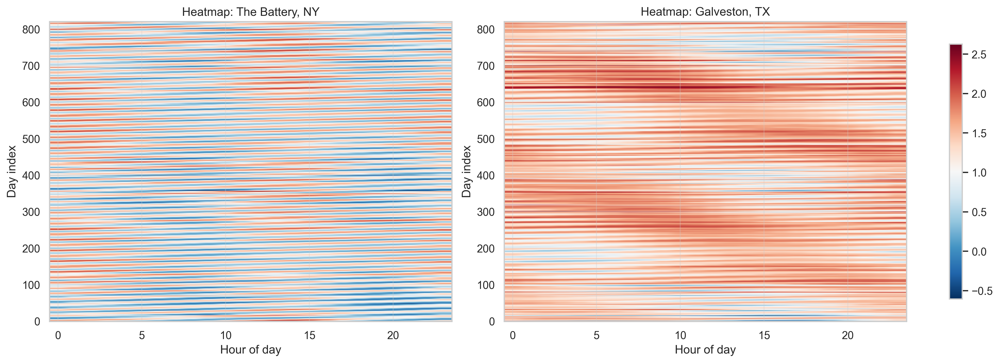

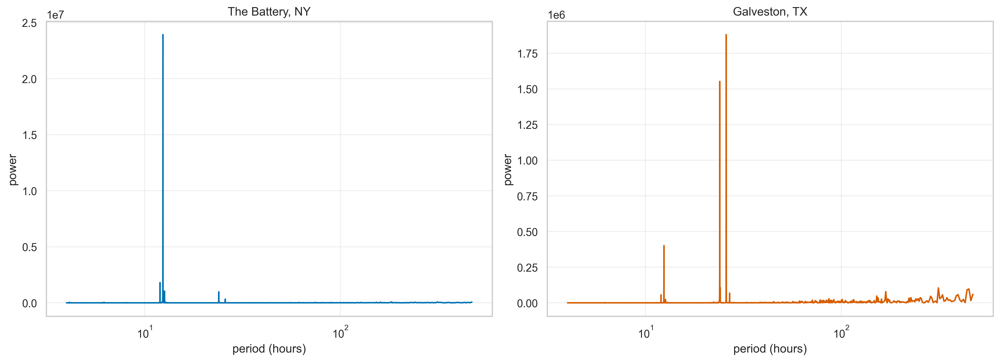

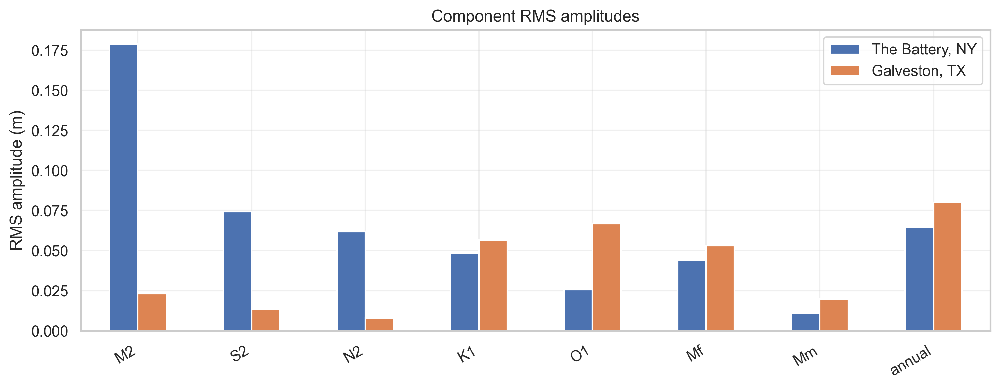

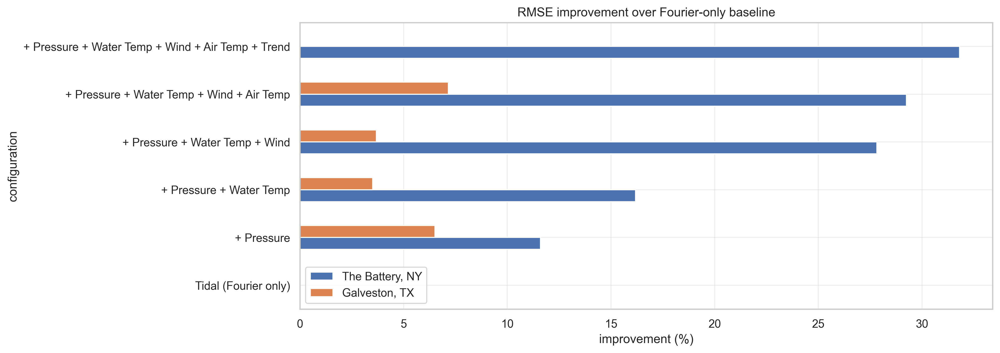

,regime,baseline_rmse,best_model,best_rmse,best_r2,regressors
"The Battery, NY",Semi-diurnal,0.2859,+ Pressure + Water Temp + Wind + Air Temp + Trend,0.1949,0.8668,"pressure, water_temp, wind_u, wind_v, air_temp"
"Galveston, TX",Diurnal/mixed,0.1884,+ Pressure + Water Temp + Wind + Air Temp,0.1749,0.4784,"pressure, water_temp, wind_u, wind_v, air_temp"


In [15]:
if comparison_df is None:
    comparison_summary = pd.DataFrame({"message": ["No comparison station configured."]})
else:
    comparison_train = comparison_df[TRAIN_START:TRAIN_END].copy()
    comparison_test = comparison_df[TEST_START:TEST_END].copy()
    for subset in (comparison_train, comparison_test):
        if subset.index.freq is None:
            subset.index.freq = pd.infer_freq(subset.index)
    comparison_y_train = comparison_train["water_level"].to_numpy()
    comparison_y_test = comparison_test["water_level"].to_numpy()

    comparison_multi_periodic = _make_multi_periodic(comparison_samples_per_hour)
    comparison_fourier_est = TsgamEstimator(
        config=TsgamEstimatorConfig(
            multi_periodic_config=comparison_multi_periodic,
            exog_config=None,
            solver_config=TsgamSolverConfig(solver=SOLVER, verbose=False),
            random_state=42,
        )
    )
    comparison_fourier_est.fit(pd.DataFrame(index=comparison_train.index), comparison_y_train)
    comparison_components = extract_fourier_components(
        comparison_fourier_est,
        labels=component_labels,
    )
    comparison_component_rms = pd.DataFrame(
        {
            "rms_amplitude": {
                name: float(np.sqrt(np.mean(comparison_components[name] ** 2)))
                for name in component_labels
                if name in comparison_components
            }
        }
    )

    comparison_wl_mask_train = comparison_train["water_level"].notna()
    comparison_wl_mask_test = comparison_test["water_level"].notna()
    comparison_regressor_cols = [
        column
        for column in regressor_candidates
        if column in comparison_df.columns
        and comparison_train.loc[comparison_wl_mask_train, column].notna().mean() > 0.99
        and comparison_test.loc[comparison_wl_mask_test, column].notna().mean() > 0.99
    ]
    for column in comparison_regressor_cols:
        comparison_train[column] = comparison_train[column].interpolate(limit_direction="both")
        comparison_test[column] = comparison_test[column].interpolate(limit_direction="both")

    comparison_means = comparison_train[comparison_regressor_cols].mean() if comparison_regressor_cols else pd.Series(dtype=float)
    comparison_stds = comparison_train[comparison_regressor_cols].std().replace(0, 1) if comparison_regressor_cols else pd.Series(dtype=float)
    comparison_X_train = (
        (comparison_train[comparison_regressor_cols] - comparison_means) / comparison_stds
        if comparison_regressor_cols
        else pd.DataFrame(index=comparison_train.index)
    )
    comparison_X_test = (
        (comparison_test[comparison_regressor_cols] - comparison_means) / comparison_stds
        if comparison_regressor_cols
        else pd.DataFrame(index=comparison_test.index)
    )

    comparison_spline_configs, comparison_default_spline = _make_spline_configs(comparison_samples_per_hour)
    comparison_configs = _build_tidal_configs(
        comparison_X_train,
        comparison_y_train,
        comparison_X_test,
        comparison_y_test,
        set(comparison_regressor_cols),
        multi_periodic=comparison_multi_periodic,
        spline_configs=comparison_spline_configs,
        default_spline=comparison_default_spline,
        solver=SOLVER,
    )
    for cfg in comparison_configs:
        if cfg.get("trend_config") is not None:
            cfg["trend_config"].grouping = 24.0 * comparison_samples_per_hour
    comparison_results = [_fit_single_tidal(cfg) for cfg in comparison_configs]
    comparison_table = pd.DataFrame(
        [
            {
                "configuration": result["name"],
                "rmse": result["rmse"],
                "r2": result["r2"],
            }
            for result in comparison_results
            if result["y_pred"] is not None
        ]
    )
    comparison_baseline_rmse = comparison_table.loc[
        comparison_table["configuration"] == "Tidal (Fourier only)",
        "rmse",
    ].iloc[0]
    comparison_table["rmse_improvement_pct"] = (
        (comparison_baseline_rmse - comparison_table["rmse"]) / comparison_baseline_rmse * 100
    )
    comparison_best_result = min(
        [result for result in comparison_results if result["y_pred"] is not None],
        key=lambda result: result["rmse"],
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    primary_heat = build_day_hour_matrix(df.index, df["water_level"].to_numpy())
    comparison_heat = build_day_hour_matrix(comparison_df.index, comparison_df["water_level"].to_numpy())
    image = axes[0].imshow(primary_heat.to_numpy(), aspect="auto", origin="lower", cmap="RdBu_r")
    axes[0].set_title(f"Heatmap: {station_meta['name']}")
    axes[0].set_xlabel("Hour of day")
    axes[0].set_ylabel("Day index")
    axes[1].imshow(comparison_heat.to_numpy(), aspect="auto", origin="lower", cmap="RdBu_r")
    axes[1].set_title(f"Heatmap: {comparison_meta['name']}")
    axes[1].set_xlabel("Hour of day")
    axes[1].set_ylabel("Day index")
    fig.colorbar(image, ax=axes, shrink=0.85)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    axes[0].plot(primary_spectrum["period_hours"], primary_spectrum["power"], color="#0072B2")
    axes[0].set_xscale("log")
    axes[0].set_title(station_meta["name"])
    axes[0].set_xlabel("period (hours)")
    axes[0].set_ylabel("power")
    axes[1].plot(comparison_spectrum["period_hours"], comparison_spectrum["power"], color="#D55E00")
    axes[1].set_xscale("log")
    axes[1].set_title(comparison_meta["name"])
    axes[1].set_xlabel("period (hours)")
    axes[1].set_ylabel("power")
    plt.show()

    common_components = [
        name for name in component_labels
        if name in component_rms.index and name in comparison_component_rms.index
    ]
    component_compare = pd.DataFrame(
        {
            station_meta["name"]: component_rms.loc[common_components, "rms_amplitude"],
            comparison_meta["name"]: comparison_component_rms.loc[common_components, "rms_amplitude"],
        }
    )
    component_compare.plot.bar(figsize=(12, 4), title="Component RMS amplitudes")
    plt.ylabel("RMS amplitude (m)")
    plt.xticks(rotation=30, ha="right")
    plt.show()

    gain_compare = pd.concat(
        [
            ablation_table.set_index("configuration")["rmse_improvement_pct"].rename(station_meta["name"]),
            comparison_table.set_index("configuration")["rmse_improvement_pct"].rename(comparison_meta["name"]),
        ],
        axis=1,
    )
    gain_compare.plot.barh(figsize=(12, 5), title="RMSE improvement over Fourier-only baseline")
    plt.xlabel("improvement (%)")
    plt.show()

    comparison_summary = pd.DataFrame(
        {
            "regime": [station_meta["tidal_regime"], comparison_meta["tidal_regime"]],
            "baseline_rmse": [baseline_rmse, comparison_baseline_rmse],
            "best_model": [best_result["name"], comparison_best_result["name"]],
            "best_rmse": [best_result["rmse"], comparison_best_result["rmse"]],
            "best_r2": [best_result["r2"], comparison_best_result["r2"]],
            "regressors": [", ".join(regressor_cols), ", ".join(comparison_regressor_cols)],
        },
        index=[station_meta["name"], comparison_meta["name"]],
    )

comparison_summary